<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%209/Latihan%20Praktikum%209_Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 9.11 Implementasi Python — Ensemble Learning (Wine)



## Praktikum 9.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (RandomForestClassifier,
    GradientBoostingClassifier, AdaBoostClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

## Praktikum 9.2 Import Dataset

In [2]:
import os
FILE = "wine.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()      # pilih file wine.csv
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

data = pd.read_csv(FILE)
y = data["Wine"].values - 1            # kelas 1,2,3 -> 0,1,2
X = data.drop(columns="Wine")
print("Ukuran data:", X.shape, "| distribusi kelas:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X.head()

Ukuran data: (178, 13) | distribusi kelas: [59 71 48]


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## Praktikum 9.3 Preprocessing dan Training Model

In [3]:
rf = RandomForestClassifier(n_estimators=300,
                            oob_score=True, random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100,
                                learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(
    X_train, y_train)

## Praktikum 9.4 Evaluasi

In [4]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))

for nama, model in [("Decision Tree Tunggal", tree_tunggal),
                    ("Random Forest", rf),
                    ("AdaBoost", ada),
                    ("Gradient Boosting", gb)]:
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Test = {acc:.3f}")

OOB Score Random Forest: 0.979
Decision Tree Tunggal: Akurasi Test = 0.944
Random Forest: Akurasi Test = 1.000
AdaBoost: Akurasi Test = 0.917
Gradient Boosting: Akurasi Test = 0.944


## Praktikum 9.5 Visualisasi

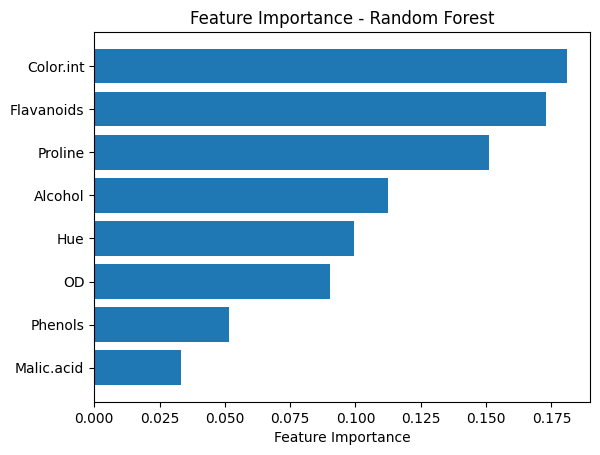

In [5]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:8]
plt.barh([X.columns[i] for i in idx][::-1],
         importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.show()

### 9.11.1 Interpretasi

- **OOB Score Random Forest = 0,979**, sejalan dengan akurasi test (1,000), sehingga tidak ada tanda overfitting. OOB adalah validasi gratis dari data yang tidak terpilih pada bootstrap tiap pohon.
- **Akurasi test (36 sampel):** Random Forest **1,000**, Decision Tree 0,944, Gradient Boosting 0,944, AdaBoost 0,917. Random Forest jelas unggul, tetapi **AdaBoost justru sedikit di bawah pohon tunggal** pada satu split ini. Pernyataan buku bahwa ensemble "umumnya" lebih baik tidak berlaku mutlak pada satu pembagian data; test set sekecil ini membuat 1 sampel setara 0,028 akurasi. Karena itu perbandingan yang andal dilakukan dengan cross-validation (Latihan 2).
- **Feature importance:** fitur paling berpengaruh adalah `Color.int` (0,181), `Flavanoids` (0,173), dan `Proline` (0,151), disusul `Alcohol`, `Hue`, dan `OD`. Ketiga fitur teratas menyumbang sekitar 50% dari seluruh importance.

---
## 9.12 Latihan Praktikum

### Praktikum 1: Pengaruh `n_estimators` (Praktikum 9.6)

In [6]:
for n in [10, 50, 100, 300, 500]:
    model = RandomForestClassifier(n_estimators=n,
                                   oob_score=True, random_state=42)
    model.fit(X_train, y_train)
    print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, "
          f"Test Acc={accuracy_score(y_test, model.predict(X_test)):.3f}")

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too fe

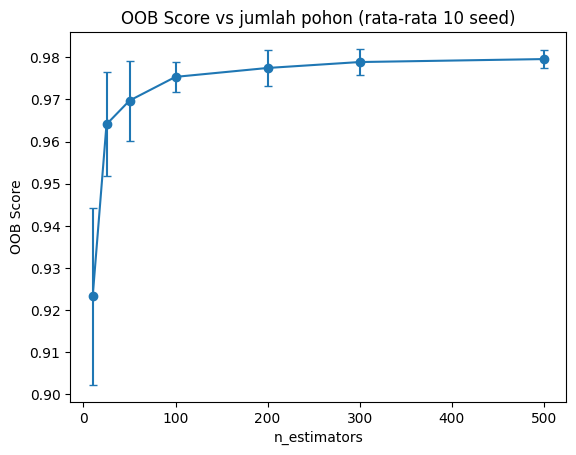

 n_estimators  OOB rata-rata  OOB std
           10          0.923    0.021
           25          0.964    0.012
           50          0.970    0.009
          100          0.975    0.004
          200          0.977    0.004
          300          0.979    0.003
          500          0.980    0.002


In [7]:
# Tambahan: kurva OOB score terhadap jumlah pohon (dengan beberapa random_state agar stabil)
ns = [10, 25, 50, 100, 200, 300, 500]
oob = np.array([[RandomForestClassifier(n_estimators=n, oob_score=True, random_state=s)
                 .fit(X_train, y_train).oob_score_ for n in ns] for s in range(10)])
plt.errorbar(ns, oob.mean(axis=0), yerr=oob.std(axis=0), marker='o', capsize=3)
plt.xlabel("n_estimators"); plt.ylabel("OOB Score")
plt.title("OOB Score vs jumlah pohon (rata-rata 10 seed)")
plt.show()
print(pd.DataFrame({"n_estimators": ns, "OOB rata-rata": oob.mean(axis=0).round(3), "OOB std": oob.std(axis=0).round(3)}).to_string(index=False))

#### Kesimpulan Praktikum 1

| n_estimators | OOB | Test Acc |
|---|---|---|
| 10 | 0,951 | 1,000 |
| 50 | 0,972 | 1,000 |
| 100 | 0,979 | 1,000 |
| 300 | 0,979 | 1,000 |
| 500 | 0,979 | 1,000 |

- **OOB naik dari 0,951 (10 pohon) ke 0,979 (100 pohon), lalu mendatar** pada random_state=42. Menambah pohon dari 100 ke 300 atau 500 tidak memberi peningkatan pada hasil ini, hanya menambah waktu komputasi. Pada dataset ini sekitar **100 pohon sudah cukup**.
- **Test Acc selalu 1,000** untuk semua nilai n, sehingga tidak bisa membedakan model (test set kecil dan sudah jenuh). Di sinilah OOB score berguna: ia tetap sensitif terhadap perubahan jumlah pohon.
- Menambah pohon **tidak menyebabkan overfitting** pada Random Forest, karena hasil akhirnya adalah rata-rata banyak pohon; efeknya hanya menurunkan variance sampai titik jenuh.
- Kurva rata-rata 10 seed menunjukkan pola yang sama: naik tajam di awal (0,923 pada 10 pohon menjadi 0,975 pada 100 pohon), lalu hanya naik sangat sedikit (sekitar 0,005 sampai 500 pohon, setara dengan simpangan baku antar seed). Simpangan baku antar seed juga mengecil dari 0,021 menjadi 0,002, artinya hasil makin stabil dengan lebih banyak pohon.

### Praktikum 2: Perbandingan Empat Model dengan Stratified k-Fold (`f1_macro`)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Rata-rata F1 macro,Std
Random Forest,0.972,1.000,1.000,0.948,1.000,0.984,0.021
AdaBoost,0.972,0.945,0.891,0.864,0.971,0.929,0.044
Gradient Boosting,0.918,0.890,0.946,0.895,0.970,0.924,0.030
Decision Tree,0.893,0.915,0.890,0.836,0.946,0.896,0.036


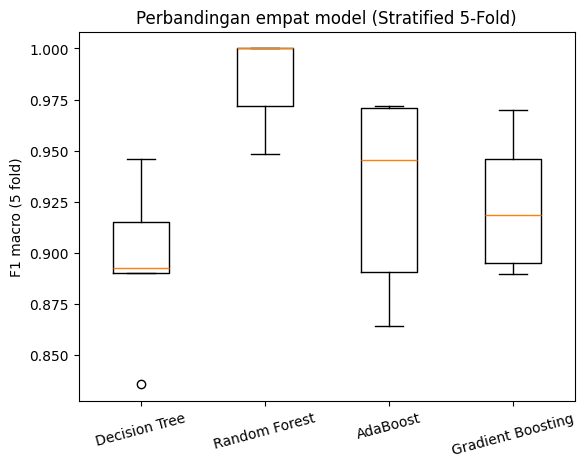

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
empat_model = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
}
skor = {n: cross_val_score(m, X, y, cv=skf, scoring="f1_macro") for n, m in empat_model.items()}

tabel = pd.DataFrame({
    "Fold 1": {n: s[0] for n, s in skor.items()}, "Fold 2": {n: s[1] for n, s in skor.items()},
    "Fold 3": {n: s[2] for n, s in skor.items()}, "Fold 4": {n: s[3] for n, s in skor.items()},
    "Fold 5": {n: s[4] for n, s in skor.items()},
    "Rata-rata F1 macro": {n: s.mean() for n, s in skor.items()},
    "Std": {n: s.std() for n, s in skor.items()}}).round(3)
display(tabel.sort_values("Rata-rata F1 macro", ascending=False))

plt.boxplot(list(skor.values()))
plt.xticks(range(1, 5), list(skor.keys()), rotation=15)
plt.ylabel("F1 macro (5 fold)"); plt.title("Perbandingan empat model (Stratified 5-Fold)")
plt.show()

#### Kesimpulan Praktikum 2

| Model | F1 macro rata-rata | Std |
|---|---|---|
| **Random Forest** | **0,984** | **0,021** |
| AdaBoost | 0,929 | 0,044 |
| Gradient Boosting | 0,924 | 0,030 |
| Decision Tree | 0,896 | 0,036 |

- **Terbaik: Random Forest** (F1 macro 0,984), unggul sekitar 0,055 dari model terbaik berikutnya, selisih yang lebih besar dari simpangan baku sehingga cukup meyakinkan. Random Forest juga **paling stabil** (std terkecil, 0,021). Ia mencapai 1,000 pada 3 dari 5 fold.
- **AdaBoost dan Gradient Boosting** setara (selisih 0,005, jauh di bawah std), keduanya lebih baik dari pohon tunggal. AdaBoost paling tidak stabil (std 0,044).
- **Decision Tree** paling rendah (0,896): satu pohon penuh mudah overfitting dan sensitif terhadap data latih (variance tinggi), yang diredam Random Forest lewat rata-rata banyak pohon.
- **Mengapa bagging mengungguli boosting di sini?** Dataset Wine kecil (178 sampel) dan bersih; boosting berfokus pada sampel sulit sehingga lebih peka terhadap sampel sulit atau noise, sedangkan Random Forest lebih tahan. Kesimpulan ini berlaku untuk dataset Wine dengan parameter bawaan, bukan aturan umum; boosting yang di-*tuning* (learning rate, kedalaman) bisa lebih baik.
- **Rekomendasi untuk dataset Wine: Random Forest.**